# Honest Forest Outlier Detection Demo**Presenter framing:** This notebook is a controlled research demo. The goal is not to claim that Honest Forests are already the best anomaly detector. The goal is to separate three related ideas:1. whether an Honest Forest can classify planted outliers,2. whether RF-GAP sparse proximities can be extracted from the fitted forest, and3. whether ENE proximity scores behave like useful anomaly-ranking scores.**Main result to emphasize:** The forests can classify the planted labels, but the ENE proximity score is much weaker as an anomaly-ranking method than Isolation Forest and Local Outlier Factor on this toy dataset.

In [ ]:
from forestgap import Proximity, embed, get_prototypes, impute, local_feature_importance, outlier_scoresclass _LegacyProximityModel:    def __init__(self, proximity):        self._proximity = proximity    def fit(self, X, y=None, **fit_kwargs):        self._proximity.fit(X, y, **fit_kwargs)        return self    def attach(self, X, y=None):        self._proximity.attach(X, y)        return self    def set_params(self, **params):        prox_params = {}        for key in ("relation", "prox_method", "matrix_type", "non_zero_diagonal", "symm_mode", "max_normalize", "random_state"):            if key in params:                prox_params[key] = params.pop(key)        if params:            self._proximity.estimator.set_params(**params)        if "prox_method" in prox_params and "relation" not in prox_params:            prox_params["relation"] = prox_params.pop("prox_method")        if prox_params:            rel = prox_params.get("relation", self._proximity.relation)            self._proximity._init_sparse_proximity(                prox_method=rel,                matrix_type=prox_params.get("matrix_type", self._proximity.matrix_type),                non_zero_diagonal=prox_params.get("non_zero_diagonal", self._proximity.non_zero_diagonal),                symm_mode=prox_params.get("symm_mode", self._proximity.symm_mode),                max_normalize=prox_params.get("max_normalize", self._proximity.max_normalize),            )            if "random_state" in prox_params:                self._proximity.random_state = prox_params["random_state"]        return self    def get_params(self, deep=True):        params = {}        try:            params.update(self._proximity.estimator.get_params(deep=deep))        except Exception:            pass        params.update({            "relation": self._proximity.relation,            "prox_method": self._proximity.relation,            "matrix_type": self._proximity.matrix_type,            "non_zero_diagonal": self._proximity.non_zero_diagonal,            "symm_mode": self._proximity.symm_mode,            "max_normalize": self._proximity.max_normalize,        })        return params    def phate(self, **kwargs):        return embed(self._proximity, method="phate", **kwargs)    def outlier_scores(self, *args, **kwargs):        return outlier_scores(self._proximity, *args, **kwargs)    def impute(self, *args, **kwargs):        return impute(self._proximity, *args, **kwargs)    def get_prototypes(self, *args, **kwargs):        return get_prototypes(self._proximity, *args, **kwargs)    def local_feature_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def local_variable_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def __getattr__(self, name):        return getattr(self._proximity, name)def compose_proximity(estimator_or_cls):    if isinstance(estimator_or_cls, type):        def _factory(*args, **kwargs):            relation = kwargs.pop("relation", kwargs.pop("prox_method", "rfgap"))            matrix_type = kwargs.pop("matrix_type", "sparse")            non_zero_diagonal = kwargs.pop("non_zero_diagonal", False)            symm_mode = kwargs.pop("symm_mode", None)            max_normalize = kwargs.pop("max_normalize", False)            random_state = kwargs.pop("random_state", None)            estimator = estimator_or_cls(*args, **kwargs)            prox = Proximity(                estimator,                relation=relation,                matrix_type=matrix_type,                non_zero_diagonal=non_zero_diagonal,                symm_mode=symm_mode,                max_normalize=max_normalize,                random_state=random_state,            )            return _LegacyProximityModel(prox)        return _factory    prox = Proximity(estimator_or_cls)    return _LegacyProximityModel(prox)

## 0. Environment Setup**What to tell the professor:** The first implementation issue was environment compatibility, not a modeling bug. `treeple` is sensitive to the Python/scikit-learn version because it relies on compiled tree internals.This notebook is intended to run in the `honest-forest` conda environment using Python 3.12.```bashconda create -y -n honest-forest python=3.12conda run -n honest-forest pip install   "scikit-learn==1.5.2" "treeple==0.9.1"   numpy scipy pandas matplotlib seaborn ipykernel jupyter```Then register the kernel:```bashconda run -n honest-forest python -m ipykernel install   --user --name honest-forest --display-name "Python (honest-forest)"```

In [39]:
from pathlib import Pathimport sysdef add_repo_root_to_path(marker: str = 'forestgap') -> Path:    cwd = Path.cwd().resolve()    for candidate in (cwd, *cwd.parents):        if (candidate / marker).exists():            path = str(candidate)            if path not in sys.path:                sys.path.insert(0, path)            return candidate    raise RuntimeError(f"Could not locate a repo root containing '{marker}'.")REPO_ROOT = add_repo_root_to_path()import numpy as npimport pandas as pdimport matplotlib.pyplot as pltfrom sklearn.datasets import make_blobsfrom sklearn.preprocessing import StandardScalerfrom treeple import HonestForestClassifierplt.style.use('seaborn-v0_8-whitegrid')RANDOM_STATE = 42rng = np.random.default_rng(RANDOM_STATE)

Imports and repo pathThis cell makes sure Python can find the local `forestgap` package, imports the modeling libraries, and sets the plot style. If something fails here, it is usually an environment/kernel issue rather than a research-method issue.

## 1. Demo Configuration**Purpose of this section:** Fix the toy experiment settings so the results are reproducible.We use 400 samples, with 5% planted outliers. That gives 20 true anomalies, which makes top-k evaluation easy to interpret: Precision@20 asks how many of the 20 highest-scored points are true planted outliers.

In [40]:
N_SAMPLES = 400TRUE_OUTLIER_FRACTION = 0.05N_ESTIMATORS = 300print('Demo configuration')print(f'  total samples:         {N_SAMPLES}')print(f'  planted outlier share: {TRUE_OUTLIER_FRACTION:.0%}')print(f'  number of trees:       {N_ESTIMATORS}')

Demo configuration
  total samples:         400
  planted outlier share: 5%
  number of trees:       300


## 2. Create a Toy Dataset**Purpose of this section:** Build a simple two-dimensional dataset where the ground truth is known.The inliers come from three Gaussian-like clusters. The planted outliers are uniformly scattered over a wider region. This makes the notebook a sanity-check setting rather than a real benchmark.**Caveat:** Since the true labels are known and later used for fitting classifier forests, this is a controlled supervised/semi-supervised demo, not a fully unsupervised anomaly detection benchmark.

In [41]:
n_inliers = int(N_SAMPLES * (1 - TRUE_OUTLIER_FRACTION))n_outliers = N_SAMPLES - n_inliersX_inliers, y_inliers = make_blobs(    n_samples=n_inliers,    centers=[(-3.0, -2.0), (0.0, 2.5), (3.5, -0.5)],    cluster_std=[0.75, 0.95, 0.70],    random_state=RANDOM_STATE,)X_outliers = rng.uniform(    low=np.array([-8.0, -7.0]),    high=np.array([8.0, 7.0]),    size=(n_outliers, 2),)X_raw = np.vstack([X_inliers, X_outliers])y_true = np.hstack([    np.zeros(n_inliers, dtype=int),    np.ones(n_outliers, dtype=int),])permutation = rng.permutation(N_SAMPLES)X_raw = X_raw[permutation]y_true = y_true[permutation]y_labels = np.hstack([y_inliers, np.full(n_outliers, -1)])[permutation]feature_names = ['feature_1', 'feature_2']X_frame = pd.DataFrame(X_raw, columns=feature_names)scaler = StandardScaler()X_scaled = scaler.fit_transform(X_frame)print(f'Inliers:  {n_inliers}')print(f'Outliers: {n_outliers}')

Inliers:  380
Outliers: 20


### Walkthrough label: Ground-truth labelsAt this point, `y_true = 0` means inlier and `y_true = 1` means planted outlier. These labels are used in two ways:1. for supervised classifier fitting, and2. for evaluation of ranking metrics.That distinction matters for the interpretation later.

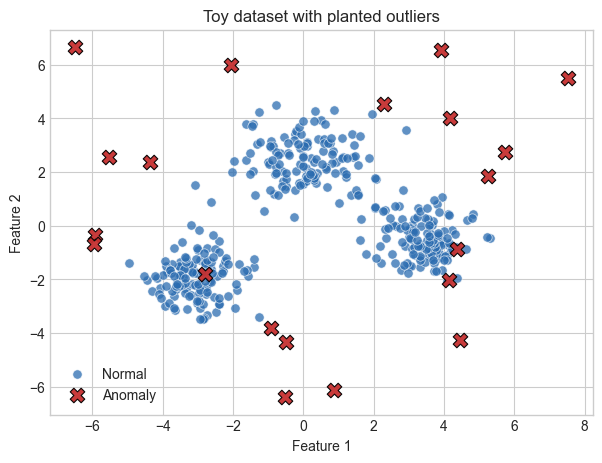

In [42]:
def scatter_anomalies(X, labels, ax, title):    normal_mask = labels == 0    anomaly_mask = labels == 1    ax.scatter(        X[normal_mask, 0],        X[normal_mask, 1],        s=45,        alpha=0.75,        c='#2b6cb0',        edgecolors='white',        linewidth=0.5,        label='Normal',    )    ax.scatter(        X[anomaly_mask, 0],        X[anomaly_mask, 1],        s=110,        alpha=0.95,        c='#c53030',        marker='X',        edgecolors='black',        linewidth=0.8,        label='Anomaly',    )    ax.set_title(title)    ax.set_xlabel('Feature 1')    ax.set_ylabel('Feature 2')    ax.legend(loc='best')fig, ax = plt.subplots(figsize=(7, 5))scatter_anomalies(X_raw, y_true, ax, 'Toy dataset with planted outliers')plt.show()

## 3. Fit an Honest Forest**Purpose of this section:** Fit the main model of interest and connect it to RF-GAP proximity computation.An Honest Forest separates tree construction from leaf estimation. That can reduce self-proximity inflation, which is why it is interesting for proximity-based scoring.**Important distinction:** Fitting `HonestForestClassifier` uses the planted labels. So the forest is first being evaluated as a supervised classifier. The proximity score evaluation later asks a different question.

In [43]:
# Wrap HonestForestClassifier with RF-GAP proximity support.# bootstrap=True is required for the rfgap method to track OOB sample indices.ProxHF = compose_proximity(HonestForestClassifier)hf_model = ProxHF(    n_estimators=N_ESTIMATORS,    bootstrap=True,    prox_method='rfgap',    random_state=RANDOM_STATE,)# Fit on binary labels: 0 = inlier, 1 = planted outlier.hf_model.fit(X_scaled, y_true)print('Honest Forest fitted.')

Honest Forest fitted.


### Walkthrough label: Main model fitThis is the main Honest Forest model. The model is fit on the toy data and labels. The important thing to say here is that this cell trains a supervised classifier, while later cells ask whether the learned forest proximity structure is useful for anomaly scoring.

## 4. Compute RF-GAP Proximities and ENE Scores**Purpose of this section:** Extract the sparse proximity matrix and convert it into an ENE score.RF-GAP proximities represent how close observations are under the forest structure. ENE stands for Effective Number of Neighbors. In theory, isolated points should have fewer effective neighbors.**Key caution:** The ENE value may act more like a neighborhood-support score than a direct anomaly score, so score direction has to be checked empirically.

In [44]:
# get_proximities() and outlier_scores() are instance methods on the fitted model.# get_proximities() returns the (n_train, n_train) sparse proximity matrix.prox_matrix = hf_model.get_proximities()# outlier_scores() accepts optional class labels (for class-relative scoring)# and the scaling / method arguments.scores = hf_model.outlier_scores(y=y_true, method='ene', scaling='normalize')print(f"Outlier scores computed for {len(scores)} samples.")

Outlier scores computed for 400 samples.


### Walkthrough label: First ENE score warningThis produces ENE scores, but at this point we have not proven that larger ENE values mean “more anomalous.” Later, we explicitly check score orientation by flipping the score direction and comparing metrics.

## 5. Visualize Honest Forest ENE Scores**Purpose of this section:** Check whether the ENE scores visually highlight planted outliers.This plot is a first qualitative check. It is useful, but not enough. The next sections add quantitative metrics and baselines.

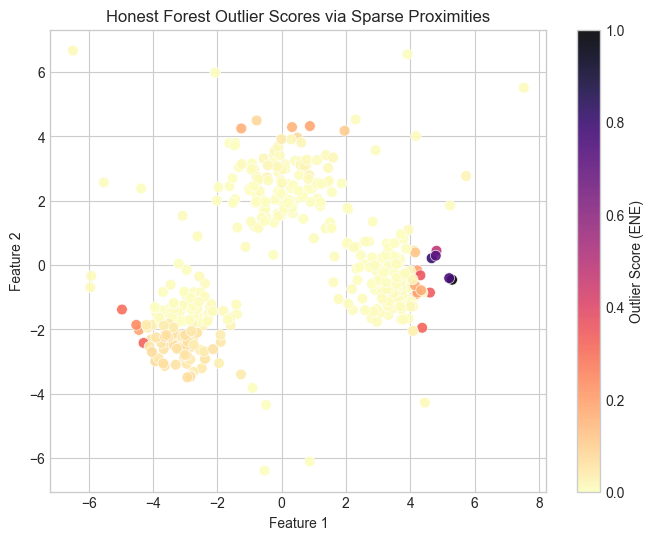

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))scatter = ax.scatter(    X_raw[:, 0],    X_raw[:, 1],    c=scores,    cmap='magma_r',    s=60,    alpha=0.9,    edgecolors='white',    linewidth=0.5,)cbar = plt.colorbar(scatter, ax=ax)cbar.set_label('Outlier Score (ENE)')ax.set_title('Honest Forest Outlier Scores via Sparse Proximities')ax.set_xlabel('Feature 1')ax.set_ylabel('Feature 2')plt.show()

## 6. Compare Honest Forest Against a Standard Random Forest**Purpose of this section:** Compare Honest Forest proximities with standard Random Forest proximities on the same data.**Research question:** Does the honesty structure change the proximity matrix enough to improve anomaly ranking?Both models use the same RF-GAP sparse proximity wrapper and the same ENE scoring method. That keeps the comparison focused on the forest type.

In [46]:
from sklearn.ensemble import RandomForestClassifierfrom sklearn.metrics import roc_auc_score, average_precision_scoreprint("Comparison tools imported.")

Comparison tools imported.


In [47]:
def fit_proximity_forest(    forest_cls,    X,    y,    *,    n_estimators=N_ESTIMATORS,    random_state=RANDOM_STATE,    model_name="Forest",    **kwargs,):    """    Fit a forest model wrapped with forestgap sparse proximity support,    then compute RF-GAP proximities and ENE outlier scores.    Parameters    ----------    forest_cls:        A forest classifier class, such as HonestForestClassifier or RandomForestClassifier.    X:        Feature matrix.    y:        Binary labels. In this demo, 0 = inlier and 1 = planted outlier.    model_name:        Human-readable model name for printed output.    kwargs:        Extra keyword arguments passed into the forest constructor.    Returns    -------    model:        Fitted forestgap-wrapped model.    prox:        Sparse proximity matrix.    scores:        ENE outlier scores.    """    ProxForest = compose_proximity(forest_cls)    model = ProxForest(        n_estimators=n_estimators,        bootstrap=True,        prox_method="rfgap",        random_state=random_state,        **kwargs,    )    model.fit(X, y)    prox = model.get_proximities()    scores = model.outlier_scores(        y=y,        method="ene",        scaling="normalize",    )    print(f"{model_name} fitted.")    print(f"  proximity matrix shape: {prox.shape}")    print(f"  proximity matrix nnz:   {prox.nnz:,}")    print(f"  score range:            {scores.min():.4f} to {scores.max():.4f}")    return model, prox, scores

In [48]:
rf_model, rf_prox_matrix, rf_scores = fit_proximity_forest(    RandomForestClassifier,    X_scaled,    y_true,    model_name="Standard Random Forest",    max_features="sqrt",    class_weight="balanced",)

Standard Random Forest fitted.
  proximity matrix shape: (400, 400)
  proximity matrix nnz:   150,597
  score range:            0.0000 to 1.0000


In [49]:
hf_scores = scoreshf_prox_matrix = prox_matrixprint("Honest Forest scores and proximities stored for comparison.")print(f"Honest Forest proximity matrix shape: {hf_prox_matrix.shape}")print(f"Honest Forest proximity matrix nnz:   {hf_prox_matrix.nnz:,}")

Honest Forest scores and proximities stored for comparison.
Honest Forest proximity matrix shape: (400, 400)
Honest Forest proximity matrix nnz:   159,464


### Walkthrough label: Honest Forest vs standard Random Forest setupBy this point, both models have proximity matrices and ENE scores. The next section evaluates whether those scores actually rank planted outliers near the top.

## 7. Quantitative Evaluation of Proximity Scores**Purpose of this section:** Move from visual inspection to ranking metrics.We evaluate the scores using the planted labels as ground truth:- **ROC-AUC:** overall ranking quality.- **PR-AUC:** more informative when outliers are rare.- **Precision@k:** how many of the top-k highest-scored points are true outliers.- **Recall@k:** how many total planted outliers are recovered in the top-k.These metrics evaluate an anomaly-ranking score. They are different from classifier accuracy and precision.

In [50]:
def precision_at_k(y_true, scores, k):    """    Precision among the top-k highest-scored observations.    """    y_true = np.asarray(y_true)    scores = np.asarray(scores)    top_k_idx = np.argsort(scores)[::-1][:k]    return y_true[top_k_idx].mean()def recall_at_k(y_true, scores, k):    """    Recall among the top-k highest-scored observations.    """    y_true = np.asarray(y_true)    scores = np.asarray(scores)    top_k_idx = np.argsort(scores)[::-1][:k]    true_positives = y_true[top_k_idx].sum()    total_positives = y_true.sum()    return true_positives / total_positivesdef evaluate_outlier_scores(y_true, scores, model_name, k=None):    """    Evaluate outlier scores using planted labels.    Higher scores are assumed to mean more anomalous.    """    if k is None:        k = int(y_true.sum())    return {        "model": model_name,        "roc_auc": roc_auc_score(y_true, scores),        "pr_auc": average_precision_score(y_true, scores),        f"precision_at_{k}": precision_at_k(y_true, scores, k),        f"recall_at_{k}": recall_at_k(y_true, scores, k),        "mean_score_inliers": np.mean(scores[y_true == 0]),        "mean_score_outliers": np.mean(scores[y_true == 1]),    }

### Walkthrough label: Score orientation diagnosticBecause ENE is related to effective neighborhood support, the raw score may not follow the convention “higher = more anomalous.” This cell creates flipped versions of the scores so we can test both directions.Flipping is not a deployment trick. It is a diagnostic to check whether the score direction is aligned with the metric convention.

In [51]:
hf_scores_flipped = -hf_scoresrf_scores_flipped = -rf_scoresflipped_results = pd.DataFrame([    evaluate_outlier_scores(y_true, hf_scores, "Honest Forest original", k=int(y_true.sum())),    evaluate_outlier_scores(y_true, hf_scores_flipped, "Honest Forest flipped", k=int(y_true.sum())),    evaluate_outlier_scores(y_true, rf_scores, "Standard RF original", k=int(y_true.sum())),    evaluate_outlier_scores(y_true, rf_scores_flipped, "Standard RF flipped", k=int(y_true.sum())),])flipped_results

,model,roc_auc,pr_auc,precision_at_20,recall_at_20,mean_score_inliers,mean_score_outliers
0,Honest Forest original,0.447763,0.044803,0.00,0.00,3.299675e-02,0.006775
1,Honest Forest flipped,0.552237,0.065013,0.00,0.00,-3.299675e-02,-0.006775
2,Standard RF original,0.434737,0.190891,0.15,0.15,9.361639e-11,0.150000
3,Standard RF flipped,0.565263,0.142227,0.20,0.20,-9.361639e-11,-0.150000


In [52]:
def top_k_metrics_table(y_true, score_dict, ks=(5, 10, 20, 40, 80, 100)):    rows = []    for model_name, scores in score_dict.items():        for k_val in ks:            rows.append({                "model": model_name,                "k": k_val,                "precision_at_k": precision_at_k(y_true, scores, k_val),                "recall_at_k": recall_at_k(y_true, scores, k_val),                "true_outliers_found": int(recall_at_k(y_true, scores, k_val) * y_true.sum()),            })    return pd.DataFrame(rows)topk_results = top_k_metrics_table(    y_true,    {        "Honest Forest flipped": hf_scores_flipped,        "Standard RF flipped": rf_scores_flipped,    },)topk_results

,model,k,precision_at_k,recall_at_k,true_outliers_found
0,Honest Forest flipped,5,0.0000,0.00,0
1,Honest Forest flipped,10,0.0000,0.00,0
2,Honest Forest flipped,20,0.0000,0.00,0
3,Honest Forest flipped,40,0.1000,0.20,4
4,Honest Forest flipped,80,0.0625,0.25,5
5,Honest Forest flipped,100,0.0500,0.25,5
6,Standard RF flipped,5,0.4000,0.10,2
7,Standard RF flipped,10,0.2000,0.10,2
8,Standard RF flipped,20,0.2000,0.20,4
9,Standard RF flipped,40,0.1500,0.30,6


### Interpretation label: Top-k retrievalThis table is useful  because it translates scores into a review workflow.Precision@20 asks, “If I review the top 20 highest-risk points, how many are actually planted outliers?” Since there are 20 planted outliers total, this is an intuitive test.**Current finding:** Standard RF retrieves some outliers earlier than Honest Forest, but both ENE-based methods are much weaker than the dedicated anomaly detection baselines.

## 8. Sanity-Check Baselines: Isolation Forest and LOF**Purpose of this section:** Test whether the dataset itself is detectable by standard anomaly detection methods.If Isolation Forest and LOF perform well, then the dataset is not the main problem. Weak ENE results would point more toward the RF-GAP/ENE scoring setup.

In [53]:
from sklearn.ensemble import IsolationForestfrom sklearn.neighbors import LocalOutlierFactor# Isolation Forest: higher score should mean more anomalous, so multiply by -1iso = IsolationForest(    n_estimators=300,    contamination=TRUE_OUTLIER_FRACTION,    random_state=RANDOM_STATE,)iso.fit(X_scaled)iso_scores = -iso.score_samples(X_scaled)# LOF with novelty=False gives negative_outlier_factor_# More negative = more outlier, so multiply by -1lof = LocalOutlierFactor(    n_neighbors=20,    contamination=TRUE_OUTLIER_FRACTION,)lof.fit_predict(X_scaled)lof_scores = -lof.negative_outlier_factor_baseline_results = pd.DataFrame([    evaluate_outlier_scores(y_true, hf_scores_flipped, "Honest Forest flipped", k=k),    evaluate_outlier_scores(y_true, rf_scores_flipped, "Standard RF flipped", k=k),    evaluate_outlier_scores(y_true, iso_scores, "Isolation Forest", k=k),    evaluate_outlier_scores(y_true, lof_scores, "Local Outlier Factor", k=k),])baseline_results

,model,roc_auc,pr_auc,precision_at_20,recall_at_20,mean_score_inliers,mean_score_outliers
0,Honest Forest flipped,0.552237,0.065013,0.00,0.00,-3.299675e-02,-0.006775
1,Standard RF flipped,0.565263,0.142227,0.20,0.20,-9.361639e-11,-0.150000
2,Isolation Forest,0.939342,0.887256,0.85,0.85,4.477214e-01,0.630059
3,Local Outlier Factor,0.949737,0.892190,0.85,0.85,1.120464e+00,3.177764


### Interpretation label: Baseline comparisonThis is one of the most important result cells.Isolation Forest and LOF perform much better than the RF-GAP ENE scores. That means the toy dataset is detectable; the weaker result is specific to the current proximity-score setup, not simply a bad dataset.

In [54]:
baseline_topk_results = top_k_metrics_table(    y_true,    {        "Honest Forest flipped": hf_scores_flipped,        "Standard RF flipped": rf_scores_flipped,        "Isolation Forest": iso_scores,        "Local Outlier Factor": lof_scores,    },)baseline_topk_results

,model,k,precision_at_k,recall_at_k,true_outliers_found
0,Honest Forest flipped,5,0.0000,0.00,0
1,Honest Forest flipped,10,0.0000,0.00,0
2,Honest Forest flipped,20,0.0000,0.00,0
3,Honest Forest flipped,40,0.1000,0.20,4
4,Honest Forest flipped,80,0.0625,0.25,5
5,Honest Forest flipped,100,0.0500,0.25,5
6,Standard RF flipped,5,0.4000,0.10,2
7,Standard RF flipped,10,0.2000,0.10,2
8,Standard RF flipped,20,0.2000,0.20,4
9,Standard RF flipped,40,0.1500,0.30,6


### Interpretation label: Baseline top-k comparisonThis table shows whether each method finds true outliers early in the ranked list. Isolation Forest and LOF should be the sanity-check reference points for whether the toy anomaly task is easy or hard.

## 9. Classifier Metrics: Accuracy, Precision, Recall, and F1**Purpose of this section:** Separate classifier performance from proximity-score performance.**Talking point:** Previously, the project used accuracy and precision. Those metrics answer: can the forest classify planted outliers? ENE ranking metrics answer a different question: do the forest proximities create a useful anomaly score?**Key interpretation:** A model can classify well while its ENE proximity scores still rank anomalies poorly.

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_reportdef evaluate_classifier_predictions(model, X, y, model_name):    y_pred = model.predict(X)    return {        "model": model_name,        "accuracy": accuracy_score(y, y_pred),        "precision": precision_score(y, y_pred, zero_division=0),        "recall": recall_score(y, y_pred, zero_division=0),        "f1": f1_score(y, y_pred, zero_division=0),        "true_outliers": int(y.sum()),        "predicted_outliers": int(y_pred.sum()),    }

In [56]:
classifier_results = pd.DataFrame([    evaluate_classifier_predictions(hf_model, X_scaled, y_true, "Honest Forest classifier"),    evaluate_classifier_predictions(rf_model, X_scaled, y_true, "Standard RF classifier"),])classifier_results

,model,accuracy,precision,recall,f1,true_outliers,predicted_outliers
0,Honest Forest classifier,0.975,1.0,0.5,0.666667,20,10
1,Standard RF classifier,1.000,1.0,1.0,1.000000,20,20


In [57]:
for model, name in [    (hf_model, "Honest Forest classifier"),    (rf_model, "Standard RF classifier"),]:    y_pred = model.predict(X_scaled)    cm = confusion_matrix(y_true, y_pred)    print(name)    print(cm)    print(classification_report(y_true, y_pred, target_names=["inlier", "outlier"], zero_division=0))    print()

Honest Forest classifier
[[380   0]
 [ 10  10]]
              precision    recall  f1-score   support

      inlier       0.97      1.00      0.99       380
     outlier       1.00      0.50      0.67        20

    accuracy                           0.97       400
   macro avg       0.99      0.75      0.83       400
weighted avg       0.98      0.97      0.97       400


Standard RF classifier
[[380   0]
 [  0  20]]
              precision    recall  f1-score   support

      inlier       1.00      1.00      1.00       380
     outlier       1.00      1.00      1.00        20

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400




### Interpretation label: Classification works better than ENE rankingThis is the key distinction to walk through carefully:- As classifiers, the forests perform well.- As ENE proximity-ranking methods, they perform weakly.The model can learn the planted labels, but the current ENE proximity score is not a strong anomaly-ranking score on this setup.

In [58]:
k = int(y_true.sum())toy_results = pd.DataFrame([    evaluate_outlier_scores(y_true, hf_scores, "Honest Forest", k=k),    evaluate_outlier_scores(y_true, rf_scores, "Standard Random Forest", k=k),])toy_results

,model,roc_auc,pr_auc,precision_at_20,recall_at_20,mean_score_inliers,mean_score_outliers
0,Honest Forest,0.447763,0.044803,0.00,0.00,3.299675e-02,0.006775
1,Standard Random Forest,0.434737,0.190891,0.15,0.15,9.361639e-11,0.150000


### Interpretation label: Raw ENE score directionThis raw-score table shows why the score-orientation diagnostic was necessary. The original ENE scores do not naturally align with “higher score = more anomalous.”

/var/folders/h6/91nlkbt916zc6n82kpz7kxtm0000gq/T/ipykernel_59470/2109948318.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


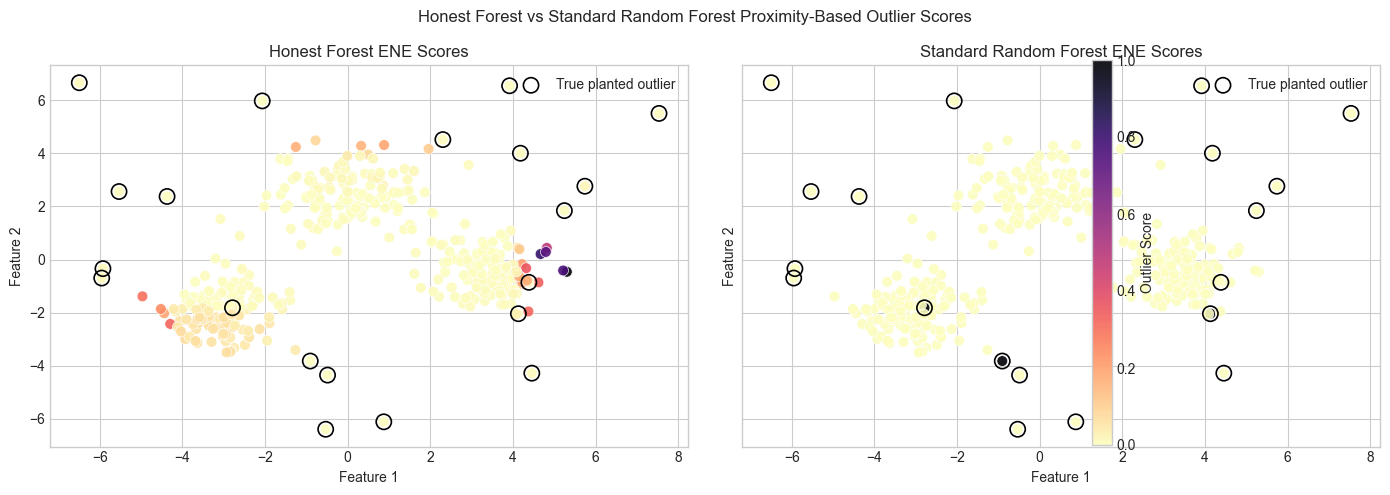

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)models_to_plot = [    ("Honest Forest ENE Scores", hf_scores),    ("Standard Random Forest ENE Scores", rf_scores),]for ax, (title, model_scores) in zip(axes, models_to_plot):    scatter = ax.scatter(        X_raw[:, 0],        X_raw[:, 1],        c=model_scores,        cmap="magma_r",        s=60,        alpha=0.9,        edgecolors="white",        linewidth=0.5,    )    ax.scatter(        X_raw[y_true == 1, 0],        X_raw[y_true == 1, 1],        s=120,        facecolors="none",        edgecolors="black",        linewidth=1.2,        marker="o",        label="True planted outlier",    )    ax.set_title(title)    ax.set_xlabel("Feature 1")    ax.set_ylabel("Feature 2")    ax.legend(loc="best")fig.colorbar(scatter, ax=axes, label="Outlier Score")plt.suptitle("Honest Forest vs Standard Random Forest Proximity-Based Outlier Scores")plt.tight_layout()plt.show()

In [60]:
def top_scored_points_table(X_raw, y_true, scores, model_name, top_n=10):    top_idx = np.argsort(scores)[::-1][:top_n]    return pd.DataFrame({        "model": model_name,        "rank": np.arange(1, top_n + 1),        "index": top_idx,        "feature_1": X_raw[top_idx, 0],        "feature_2": X_raw[top_idx, 1],        "score": scores[top_idx],        "true_outlier": y_true[top_idx],    })top_points = pd.concat([    top_scored_points_table(X_raw, y_true, hf_scores, "Honest Forest", top_n=10),    top_scored_points_table(X_raw, y_true, rf_scores, "Standard Random Forest", top_n=10),])top_points

,model,rank,index,feature_1,feature_2,score,true_outlier
0,Honest Forest,1,25,5.301352,-0.458547,1.000000e+00,0
1,Honest Forest,2,171,4.665832,0.210059,8.162634e-01,0
2,Honest Forest,3,137,5.212026,-0.409545,7.647106e-01,0
3,Honest Forest,4,320,4.794269,0.288596,7.277834e-01,0
4,Honest Forest,5,292,4.817417,0.441794,4.776145e-01,0
5,Honest Forest,6,242,4.317447,-0.321905,3.630169e-01,0
6,Honest Forest,7,1,4.615231,-0.857851,3.401263e-01,0
7,Honest Forest,8,228,-4.293688,-2.421716,3.267806e-01,0
8,Honest Forest,9,164,4.372260,-1.951373,3.205482e-01,0
9,Honest Forest,10,106,-4.964809,-1.383573,2.994004e-01,0


## 10. Final Presentation Summary**Main takeaway:** This notebook separates supervised classification from proximity-based anomaly scoring.1. The Honest Forest and standard Random Forest can be fit on the planted-label toy dataset.2. RF-GAP sparse proximities can be extracted from both forests.3. ENE proximity scores do not perform well as anomaly-ranking scores in this setup.4. Isolation Forest and LOF perform much better, which shows the toy dataset itself is detectable.5. Classifier metrics are much stronger than ENE ranking metrics, so classification performance and proximity-score performance should not be treated as the same thing.> The pipeline runs, but the current result suggests that RF-GAP ENE scores are not automatically equivalent to good anomaly scores. The next research question is whether the issue comes from the ENE score definition, the supervised fitting setup, or the use of classifier forests for proximity-based anomaly ranking.- Compare ENE against other RF-GAP score definitions, such as Breiman-style scores.- Add a train/test split so classifier performance is not only in-sample.- Test whether probability scores from the classifiers align better with planted labels than ENE scores.- Try an unsupervised or semi-supervised forest setup where labels are used only for evaluation.